## Lab 5: Performance and Scalability

### Question 1: Vectorization

The objective of this task is to perform a mathematical calculation on one million numerical values using NumPy vectorization.

The expression to calculate is:

\[
y = x^2 + 2x + 1
\]

Vectorization allows NumPy to perform mathematical operations on entire arrays without requiring explicit Python loops. This improves computational efficiency when working with large datasets.

In [1]:
import numpy as np

In [2]:
# Generate one million values
x = np.arange(1_000_000)

# Display the first 10 values
print("First 10 values: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:5")
print(x[:10])

# Display the total number of values
print("\nTotal number of values: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:9", len(x))

First 10 values: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:5
[0 1 2 3 4 5 6 7 8 9]

Total number of values: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:9 1000000


In [3]:
# Perform vectorized calculation
y = x**2 + 2*x + 1

# Display the first 10 results
print("First 10 results: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:5")
print(y[:10])

# Display the total number of results
print("\nTotal number of results: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:9", len(y))

First 10 results: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:5
[  1   4   9  16  25  36  49  64  81 100]

Total number of results: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:9 1000000


In [4]:
# Verify the calculation
verification = np.all(y == (x + 1)**2)

print("Calculation verified: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:4", verification)

Calculation verified: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:4 True


### Interpretation

The calculation was successfully performed on one million numerical values using NumPy vectorization.

The expression \(y=x^2+2x+1\) was evaluated element-wise across the entire array without using an explicit Python loop.

The verification returned True, confirming that the calculated results were correct.

Vectorization improves computational efficiency by using optimized numerical operations instead of repeatedly executing individual Python instructions.

### Question 2: Summing Squares Using Numba

The objective of this task is to implement a function that calculates the sum of squared values using Numba.

Numba is a Python library that uses Just-In-Time (JIT) compilation to accelerate numerical computations.

The mathematical expression is:

\[
S = \sum_{i=1}^{n}x_i^2
\]

The function will use Numba's `@njit` decorator to compile the Python function into optimized machine code.

In [5]:
import numpy as np
from numba import njit

In [6]:
@njit
def sum_squares(x):
    total = 0

    for value in x:
        total += value * value

    return total

In [7]:
# Create a sample array
numbers = np.array([1, 2, 3, 4, 5])

# Calculate the sum of squares
result = sum_squares(numbers)

# Display the result
print("Sum of squares: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:8", result)

Sum of squares: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:8 55


In [8]:
# Generate one million values
large_array = np.arange(1_000_000)

# Calculate the sum of squares
large_result = sum_squares(large_array)

print("Sum of squares for one million values: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:7")
print(large_result)

Sum of squares for one million values: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:7
333332833333500000


In [9]:
# Calculate using NumPy
numpy_result = np.sum(large_array ** 2)

# Compare both results
print("Numba result: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:5", large_result)
print("NumPy result: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:6", numpy_result)

print("Results match: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:8", large_result == numpy_result)

Numba result: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:5 333332833333500000
NumPy result: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:6 333332833333500000
Results match: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:8 True


### Interpretation

The Numba function successfully calculated the sum of squared values using the `@njit` decorator.

The function was tested using a small sample array and a larger array containing one million values.

The results were verified against NumPy's sum operation and both implementations produced identical results.

Numba improves computational performance by compiling Python functions into optimized machine code using Just-In-Time compilation.

### Question 3: Parallel Bootstrap Using Joblib

The objective of this task is to perform bootstrap resampling to estimate a sample mean using Joblib.

Bootstrapping involves repeatedly drawing samples from an original dataset with replacement and calculating a statistic such as the mean.

Joblib allows independent bootstrap calculations to execute in parallel, improving computational efficiency.

The bootstrap sample mean is calculated as:

\[
\bar{x}^{*} = \frac{1}{n}\sum_{i=1}^{n}x_i^{*}
\]

where \(x_i^{*}\) represents observations selected through bootstrap resampling.

In [12]:
%pip install joblib

  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
from joblib import Parallel, delayed

In [2]:
# Set random seed for reproducibility
np.random.seed(42)

# Create the original dataset
data = np.array([12, 15, 18, 20, 22, 25, 28, 30, 32, 35])

# Calculate the original sample mean
original_mean = np.mean(data)

print("Original dataset: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:10", data)
print("Original sample mean: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:11", original_mean)

Original dataset: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:10 [12 15 18 20 22 25 28 30 32 35]
Original sample mean: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:11 23.7


In [3]:
def bootstrap_mean(data, seed):
    # Create a random number generator
    rng = np.random.default_rng(seed)

    # Draw a bootstrap sample with replacement
    sample = rng.choice(data, size=len(data), replace=True)

    # Calculate and return the sample mean
    return np.mean(sample)

In [4]:
# Number of bootstrap repetitions
n_bootstrap = 1000

# Perform bootstrap resampling in parallel
bootstrap_means = Parallel(n_jobs=-1)(
    delayed(bootstrap_mean)(data, seed)
    for seed in range(n_bootstrap)
)

# Convert results into a NumPy array
bootstrap_means = np.array(bootstrap_means)

print("Number of bootstrap samples: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:13", len(bootstrap_means))
print("Bootstrap mean: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:14", np.mean(bootstrap_means))
print("Bootstrap standard deviation: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:15", np.std(bootstrap_means))

Number of bootstrap samples: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:13 1000
Bootstrap mean: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:14 23.795900000000003
Bootstrap standard deviation: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:15 2.298158652051681


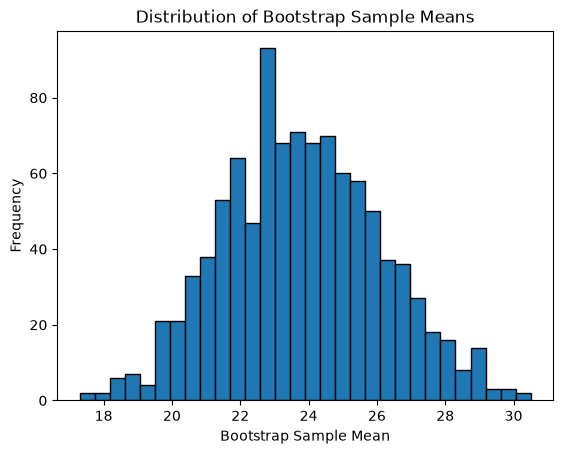

In [5]:
import matplotlib.pyplot as plt

plt.hist(bootstrap_means, bins=30, edgecolor="black")

plt.xlabel("Bootstrap Sample Mean")
plt.ylabel("Frequency")
plt.title("Distribution of Bootstrap Sample Means")

plt.show()

### Interpretation

The bootstrap procedure successfully generated 1,000 resampled datasets from the original observations.

Each bootstrap sample contained the same number of observations as the original dataset, with replacement.

Joblib distributed the independent bootstrap calculations across available CPU cores using parallel processing.

The resulting bootstrap means form an approximate sampling distribution of the sample mean. This distribution helps us understand the variability of the estimated population mean.

### Question 4: Dask Array – Mean of a Large Chunked Array

The objective of this task is to use Dask Array to calculate the mean of a large dataset.

Dask is a Python library designed for parallel and distributed computing. It allows us to work with large datasets by dividing them into smaller sections called **chunks**.

Unlike NumPy, which generally performs computations immediately, Dask uses lazy evaluation. This means that calculations are not executed immediately but are represented as tasks until we explicitly request the result.

In this exercise, we will:

1. Create a large array using Dask.
2. Divide the array into smaller chunks.
3. Calculate the mean of the array.
4. Use `.compute()` to execute the calculation and obtain the final result.


In [7]:
%pip install "dask[array]"

  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.5 MB ? eta -:--:--
   -------------- ------------------------- 0.5/1.5 MB 1.5 MB/s eta 0:00:01
   --------------------- ------------------ 0.8/1.5 MB 2.1 MB/s eta 0:00:01
   ---------------------------------------- 1.5/1.5 MB 2.4 MB/s  0:00:00
Using cached fsspec-2026.9.0-py3-none-any.whl (221 kB)

   ---------------------------------------- 0/6 [toolz]
   ------------- -------------------------- 2/6 [fsspec]
   ------------- -------------------------- 2/6 [fsspec]
   ------------- -------------------------- 2/6 [fsspec]
   -------------------- ------------------- 3/6 [click]
   -------------------------- ------------- 4/6 [partd]
   --------------------------------- ------ 5/6 [dask]
   --------------------------------- ------ 5/6 [dask]
   --------------------------------- ------ 5/6 [dask]
   ---------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch 2.14.1 requires networkx>=2.5.1, which is not installed.


In [8]:
import dask.array as da
import numpy as np

print("Dask and NumPy imported successfully!")

Dask and NumPy imported successfully!


In [9]:
# Create a large Dask array
x = da.random.random(
    size=(5_000_000,),
    chunks=(1_000_000,)
)

print("Array created successfully! - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:7")
print("Array size: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:8", x.shape)
print("Chunk sizes: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:9", x.chunks)

Array created successfully! - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:7
Array size: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:8 (5000000,)
Chunk sizes: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:9 ((1000000, 1000000, 1000000, 1000000, 1000000),)


In [10]:
# Calculate the mean using Dask
mean_value = x.mean()

print("Dask mean calculation created successfully! - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:4")

Dask mean calculation created successfully! - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:4


In [11]:
# Execute the computation
result = mean_value.compute()

print("Mean of the large array: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:4", result)

Mean of the large array: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:4 0.49987057769724597


### Interpretation

The Dask Array successfully generated a dataset containing five million random values and divided it into five smaller chunks of one million values each.

The mean was calculated using Dask's lazy evaluation mechanism. The `.compute()` method executed the pending computation and returned the final result.

The calculated mean was approximately 0.5, which is expected because the random values were generated from a uniform distribution between 0 and 1.

This demonstrates how Dask can handle large datasets efficiently by dividing computations into smaller tasks.


### Question 5: Numba Compilation and Benchmark Timing

Numba uses Just-In-Time (JIT) compilation to convert Python functions into optimized machine code.

When a Numba-decorated function is called for the first time, Numba must compile the function before executing it.

This compilation process introduces additional overhead, making the first execution slower than subsequent executions.

Therefore, the first compilation call should be excluded from benchmark timing to ensure that performance measurements reflect the actual execution speed of the compiled function.


In [12]:
import numpy as np
from numba import njit
import time

@njit
def sum_squares(x):
    total = 0
    for value in x:
        total += value * value
    return total

numbers = np.arange(1_000_000)

# First call: includes compilation time
start = time.time()
result = sum_squares(numbers)
first_time = time.time() - start

print("First execution result:", result)
print("First execution time:", first_time)

First execution result: 333332833333500000
First execution time: 0.41069674491882324


In [13]:
# Second call: function is already compiled
start = time.time()
result = sum_squares(numbers)
second_time = time.time() - start

print("Second execution result: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:6", result)
print("Second execution time: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:7", second_time)

Second execution result: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:6 333332833333500000
Second execution time: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:7 0.0006930828094482422


In [14]:
print("First execution: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:1", first_time)
print("Second execution: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:2", second_time)

if first_time > second_time:
    print("The first execution was slower due to compilation overhead. - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:5")
else:
    print("The execution times were similar or affected by system conditions. - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:7")

First execution: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:1 0.41069674491882324
Second execution: - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:2 0.0006930828094482422
The first execution was slower due to compilation overhead. - ICD341_Lab13_Mwila_Singoma_202401774.ipynb:5


### Interpretation

The first execution of the Numba function includes Just-In-Time (JIT) compilation overhead. This makes the initial execution slower than subsequent executions.

After compilation, Numba executes the optimized machine code, resulting in faster execution.

Therefore, the first compilation call should be excluded from performance benchmarking to obtain a fair measurement of the function's actual execution speed.
